Pharma Sales data

1. Data import

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

In [6]:
# Loading data set

df = pd.read_csv('/content/salesdaily.csv')

df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


2. Sales per drug category

Total sales by class:
N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


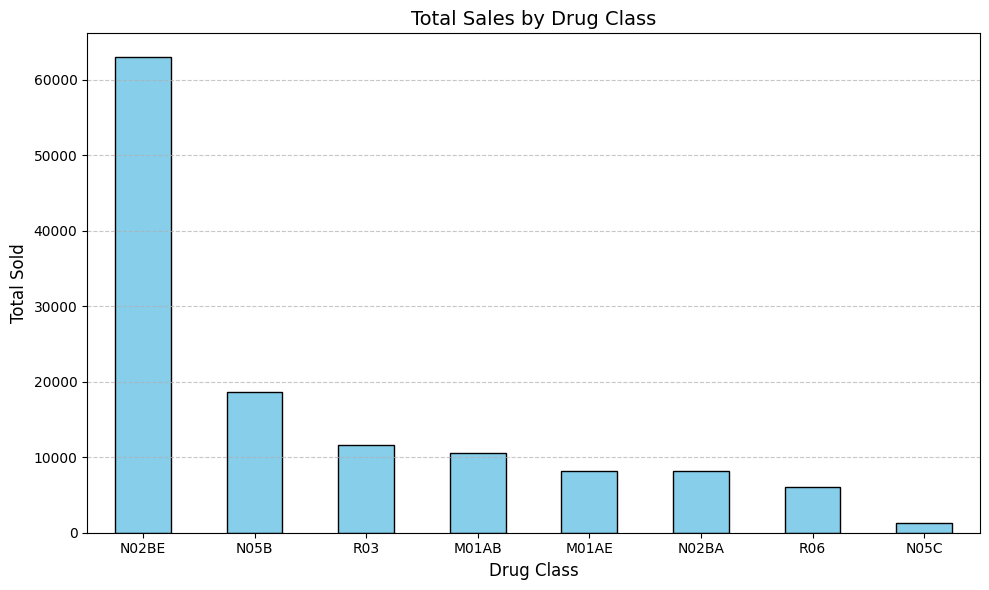

In [28]:
# Define drug class columns
drug_class = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

# Sum total sales per drug class
sales_by_class = df[drug_class].sum().sort_values(ascending=False)

# Print values
print("Total sales by class:")
print(sales_by_class)

# Create bar chart
plt.figure(figsize=(10, 6))
sales_by_class.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Total Sales by Drug Class', fontsize=14)
plt.xlabel('Drug Class', fontsize=12)
plt.ylabel('Total Sold', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Print graph
plt.tight_layout()
plt.show()

3. Which three drugs have the highest sales in January 2015, July 2016, September 2017

--- Top 3 Drugs in January 2015 ---
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

--- Top 3 Drugs in July 2016 ---
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

--- Top 3 Drugs in September 2017 ---
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


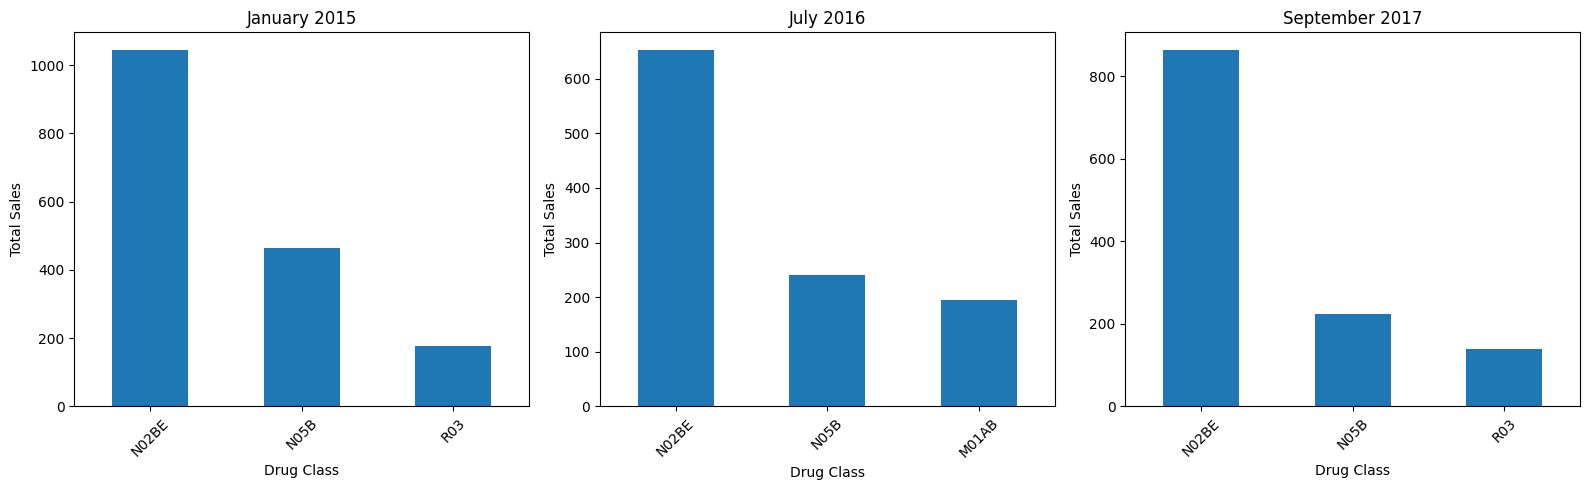

In [9]:
#Group by each period
# January 2015
jan_2015_top3 = df[(df['Year'] == 2015) & (df['Month'] == 1)][drug_class].sum().nlargest(3)

# July 2016
jul_2016_top3 = df[(df['Year'] == 2016) & (df['Month'] == 7)][drug_class].sum().nlargest(3)

# September 2017
sep_2017_top3 = df[(df['Year'] == 2017) & (df['Month'] == 9)][drug_class].sum().nlargest(3)

# Print results
print("--- Top 3 Drugs in January 2015 ---")
print(jan_2015_top3)

print("\n--- Top 3 Drugs in July 2016 ---")
print(jul_2016_top3)

print("\n--- Top 3 Drugs in September 2017 ---")
print(sep_2017_top3)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plotting graphs
# January 2015
jan_2015_top3.plot(kind='bar', ax=axes[0])
axes[0].set_title('January 2015')
axes[0].set_xlabel('Drug Class')
axes[0].set_ylabel('Total Sales')
axes[0].tick_params(axis='x', rotation=45)

# July 2016
jul_2016_top3.plot(kind='bar', ax=axes[1])
axes[1].set_title('July 2016')
axes[1].set_xlabel('Drug Class')
axes[1].set_ylabel('Total Sales')
axes[1].tick_params(axis='x', rotation=45)

# September 2017
sep_2017_top3.plot(kind='bar', ax=axes[2])
axes[2].set_title('September 2017')
axes[2].set_xlabel('Drug Class')
axes[2].set_ylabel('Total Sales')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

4. Which drug has sold the most often in 2017

In [10]:
# Filter data for 2017 and sum sales by drug class
sales_2017 = df[df['Year'] == 2017][drug_class].sum()

# Find the drug class with the highest sales
top_drug_2017 = sales_2017.idxmax()
top_sales_2017 = sales_2017.max()

print("Drug class with the highest sales in 2017:", top_drug_2017)
print("Total sales:", top_sales_2017)

Drug class with the highest sales in 2017: N02BE
Total sales: 9258.80483333


5. Which drug category has the highest average daily sales?



In [1]:
# Convert column Datum to datetime format
df['datum'] = pd.to_datetime(df['datum'], format='%m/%d/%Y')

# Calculate total sales per day for each drug category
daily_sales = df.groupby('datum')[drug_class].sum()

# Calculate average daily sales for each category
average_daily_sales = daily_sales.mean()

# Find the category with the highest average daily sales
top_category = average_daily_sales.idxmax()
top_average = average_daily_sales.max()

print("Drug category with the highest average daily sales:", top_category)
print("Average daily sales:", top_average)

NameError: name 'pd' is not defined

6. Are respiratory drugs (R03) sold more during specific months?

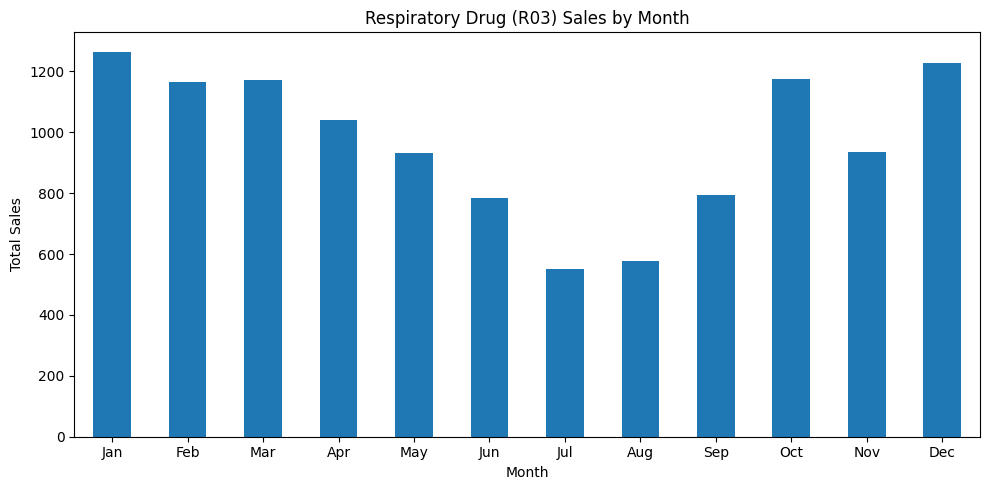

Month with highest sales: 1
Highest total sales: 1264.656250002


In [17]:
# Extract month
df['Month'] = df['datum'].dt.month

# Calculate total R03 sales by month
monthly_sales = df.groupby('Month')['R03'].sum()

# Plot the results
monthly_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Respiratory Drug (R03) Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(
    ticks=range(12),
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    rotation=0
)

plt.tight_layout()
plt.show()

print("Month with highest sales:", monthly_sales.idxmax())
print("Highest total sales:", monthly_sales.max())

7. Forecast: What medicine sales may be in January 2020?

,Forecast January 2020
N02BE,875.308851
R03,222.009200
N05B,217.721025
M01AB,161.173359
M01AE,114.441775
R06,105.038516
N02BA,82.285854
N05C,17.682919


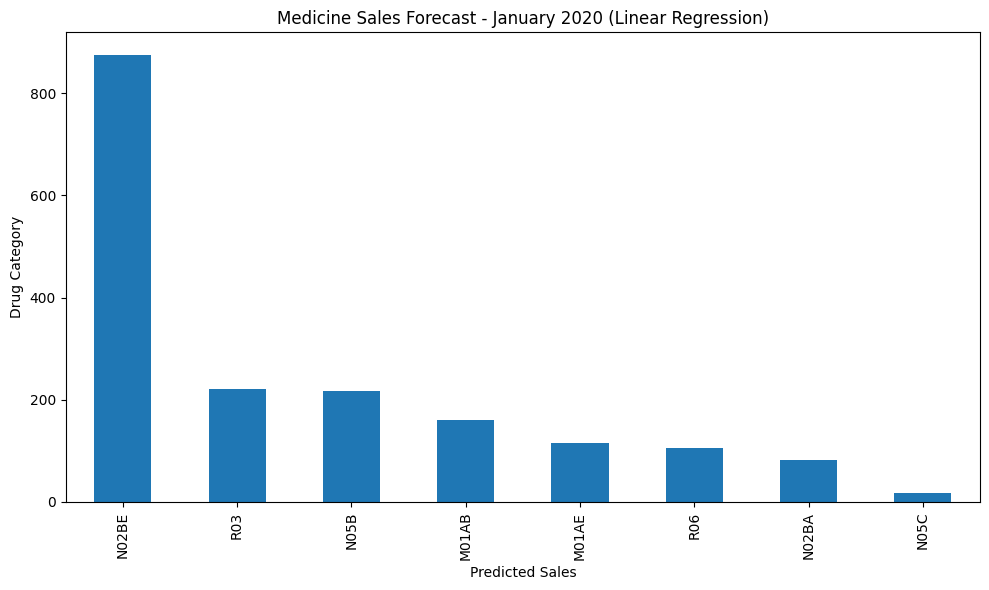

In [29]:
# Adjusting date time format
df['datum'] = pd.to_datetime(
    df['datum'], format='%m/%d/%Y'
)

monthly_sales = df.set_index('datum')[drug_class].resample('MS').sum()

# Create index
X = pd.Series(range(len(monthly_sales))).values.reshape(-1, 1)
X_future = [[len(monthly_sales)]]

forecast = {}

for drug in drug_class:
    y = monthly_sales[drug].values

    model = LinearRegression()
    model.fit(X, y)

    forecast[drug] = max(0, model.predict(X_future)[0])

forecast_jan_2020 = pd.Series(
    forecast, name='Forecast January 2020'
).sort_values(ascending=False)

display(forecast_jan_2020.to_frame())

# Create the forecast chart
plt.figure(figsize=(10, 6))
forecast_jan_2020.plot(kind='bar')

plt.title('Medicine Sales Forecast - January 2020 (Linear Regression)')
plt.xlabel('Predicted Sales')
plt.ylabel('Drug Category')

plt.tight_layout()
plt.show()